<a href="https://colab.research.google.com/github/santiagoleguizamon10/TP-labo/blob/main/tp__labo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Trabajo práctico - Influencia de la localia en el futbol argentino ⚽**


## Objetivo del trabajo practico

Este trabajo práctico busca mostrar como varia el rendimiento de los equipos argentinos cuando juegan en condicion de local y compararlo respecto a su desempeño como visitante durante el torneo clausura


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Carga del dataset
df = pd.read_csv('data/Clausura26_tp_labo.csv')

In [37]:
display(df.head())
display(df.tail())

,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
0,Fecha 1,Club Atlético Belgrano,Rosario Central,2,1,48%,52%,1.50,1.39,13,...,5,3,6,6,10,13,0.0,2.0,0,0
1,Fecha 1,Sarmiento,Argentinos Juniors,2,3,45%,55%,1.50,1.42,12,...,3,5,7,2,15,14,3.0,6.0,0,1
2,Fecha 1,Defensa y Justicia,Aldosivi,1,1,72%,28%,1.06,0.59,15,...,5,3,6,2,9,15,2.0,3.0,0,0
3,Fecha 1,Gimnasia y Esgrima Mendoza,Central Córdoba,1,0,63%,37%,1.62,1.43,22,...,8,3,3,3,6,13,0.0,1.0,0,0
4,Fecha 1,Racing Club,Gimnasia y Esgrima,2,1,57%,43%,1.42,1.89,18,...,7,5,4,3,10,12,1.0,3.0,0,0


,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
189,Fecha 13,Estudiantes de Río Cuarto,Aldosivi,2,1,52%,48%,2.12,1.23,22,...,5,4,7,0,14,12,4.0,1.0,0,0
190,Fecha 13,Club Atlético Belgrano,River Plate,0,3,42%,58%,1.04,1.14,12,...,4,7,4,7,11,19,3.0,2.0,0,0
191,Fecha 13,Newell's Old Boys,Central Córdoba,2,1,61%,39%,1.92,0.40,19,...,7,2,6,3,14,14,3.0,5.0,0,0
192,Fecha 13,Sarmiento,Barracas Central,1,1,28%,72%,0.74,2.70,7,...,2,6,1,4,17,12,2.0,1.0,0,0
193,Fecha 13,Deportivo Riestra,Club Atlético Unión de Santa Fe,1,1,35%,65%,0.80,0.68,13,...,3,5,3,4,13,13,1.0,1.0,0,0


In [38]:
print(f"Dimensiones: {df.shape[0]} filas y {df.shape[1]} columnas\n")
print("Tipos de datos (.dtypes):")
print(df.dtypes)
print(f"\nCobertura temporal: {df['Fecha'].nunique()} fechas del torneo.")

Dimensiones: 194 filas y 21 columnas

Tipos de datos (.dtypes):
Fecha                           str
Local                           str
Visitante                       str
Resultado (L)                 int64
Resultado (V)                 int64
Posesión de balón (L)           str
Posesión de balón (V)           str
Goles esperados (xG) (L)    float64
Goles esperados (xG) (V)    float64
Tiros totales (L)             int64
Tiros totales (V)             int64
Tiros al arco (L)             int64
Tiros al arco (V)             int64
Córners (L)                   int64
Córners (V)                   int64
Faltas (L)                    int64
Faltas (V)                    int64
Tarjetas amarillas (L)      float64
Tarjetas amarillas (V)      float64
Tarjetas rojas (L)            int64
Tarjetas rojas (V)            int64
dtype: object

Cobertura temporal: 13 fechas del torneo.


In [39]:
print("Valores Nulos por columna:")
print(df.isnull().sum())

print(f"\nFilas duplicadas: {df.duplicated().sum()}")

print("\nEstadísticas descriptivas:")
display(df.describe())

Valores Nulos por columna:
Fecha                       0
Local                       0
Visitante                   0
Resultado (L)               0
Resultado (V)               0
Posesión de balón (L)       0
Posesión de balón (V)       0
Goles esperados (xG) (L)    0
Goles esperados (xG) (V)    0
Tiros totales (L)           0
Tiros totales (V)           0
Tiros al arco (L)           0
Tiros al arco (V)           0
Córners (L)                 0
Córners (V)                 0
Faltas (L)                  0
Faltas (V)                  0
Tarjetas amarillas (L)      4
Tarjetas amarillas (V)      4
Tarjetas rojas (L)          0
Tarjetas rojas (V)          0
dtype: int64

Filas duplicadas: 0

Estadísticas descriptivas:


,Resultado (L),Resultado (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),Tiros totales (V),Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
count,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,190.000000,190.000000,194.000000,194.000000
mean,1.247423,1.036082,1.372010,1.078608,14.932990,11.860825,4.721649,3.840206,5.221649,3.974227,11.788660,12.190722,2.057895,2.563158,0.056701,0.118557
std,1.008060,0.962368,0.738883,0.654642,5.499001,4.287131,2.286442,2.113424,2.842561,2.224302,3.674823,3.835979,1.239481,1.326854,0.231869,0.354638
min,0.000000,0.000000,0.190000,0.040000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,4.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,0.250000,0.000000,0.762500,0.580000,11.000000,9.000000,3.000000,2.000000,3.000000,2.000000,9.000000,9.250000,1.000000,2.000000,0.000000,0.000000
50%,1.000000,1.000000,1.300000,0.970000,15.000000,11.000000,4.000000,3.500000,5.000000,4.000000,12.000000,12.000000,2.000000,2.500000,0.000000,0.000000
75%,2.000000,2.000000,1.847500,1.427500,18.000000,14.000000,6.000000,5.000000,7.000000,5.000000,14.000000,15.000000,3.000000,3.000000,0.000000,0.000000
max,5.000000,4.000000,3.540000,3.640000,30.000000,26.000000,11.000000,12.000000,14.000000,10.000000,25.000000,24.000000,6.000000,6.000000,1.000000,2.000000


**Conclusiones de la exploración:**
No se observan filas duplicadas. Sin embargo, en el análisis de calidad detectamos lo siguiente:
1. **Datos faltantes (filas):** Al haber 13 fechas disputadas y 194 filas en total, se deduce que falta registrar al menos un partido en el dataset.
2. **Valores nulos:** Hay columnas con nulos (específicamente en las tarjetas amarillas) que deben ser imputados con 0.
3. **Tipos de datos:** Las columnas de posesión figuran como tipo texto (`object`) debido al símbolo `%`, por lo que es necesario limpiarlas y convertirlas a formato numérico para poder realizar cálculos.

In [40]:
# Limpieza de nulos en tarjetas
cols_tarjetas = ['Tarjetas amarillas (L)', 'Tarjetas amarillas (V)', 'Tarjetas rojas (L)', 'Tarjetas rojas (V)']
df[cols_tarjetas] = df[cols_tarjetas].fillna(0)

# Conversión de posesión a numérico
df['Posesión de balón (L)'] = df['Posesión de balón (L)'].str.replace('%', '').astype(int)
df['Posesión de balón (V)'] = df['Posesión de balón (V)'].str.replace('%', '').astype(int)

print("Datos limpios y listos para el análisis.")

Datos limpios y listos para el análisis.




## Estadísticas defensivas según la condición (Local vs. Visitante)

En este apartado, analizaremos el rendimiento defensivo de los equipos aislando completamente las variables de ataque y posesión. El objetivo es evaluar tanto la fricción física como la permeabilidad táctica de los sistemas defensivos dependiendo del estadio en el que se juegue.

Para medir esto, utilizaremos exclusivamente las siguientes métricas:

* **Tiros recibidos:** Mide el volumen de remates que el equipo le concede al rival.
* **Tiros al arco recibidos:** Mide el volumen de llegadas efectivas que la defensa le permite al oponente.
* **Goles esperados (xG) concedidos:** Evalúa la calidad y el nivel de peligro real de las ocasiones que el equipo rival logra generar.

El análisis de esta sección se estructurará en tres partes fundamentales:

* **Nivel Global:** Veremos las estadísticas generales de la liga completa para comprender el efecto estructural de jugar fuera de casa.
* **Grandes vs. Resto:** Compararemos a los 5 equipos grandes contra el resto de la liga para comprobar si la jerarquía del plantel logra anular la vulnerabilidad visitante.
* **Los 5 Grandes entre sí:** Aislaremos a los equipos más populares para identificar los diferentes estilos y tácticas defensivas que aplican al salir de su estadio.


### 1. Análisis Global: El impacto estructural de la localía

A continuación, procesaremos el dataset para reestructurarlo bajo un enfoque puramente defensivo y generaremos diagramas de caja (Boxplots) para comparar la distribución de las métricas en toda la Liga Profesional.

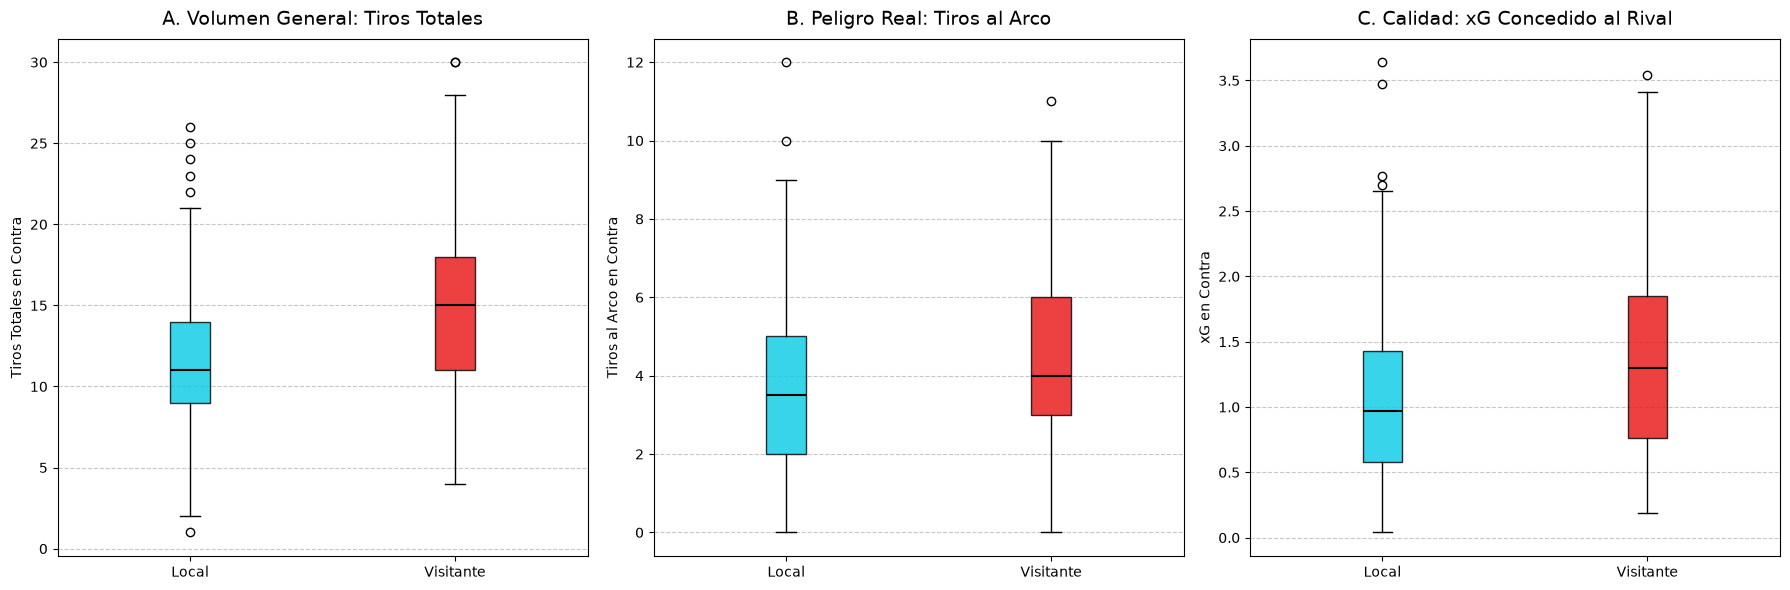

--- Medianas Globales ---
           Tiros Totales Concedidos  Tiros Arco Concedidos  xG Concedido
Condicion                                                               
Local                          11.0                    3.5          0.97
Visitante                      15.0                    4.0          1.30


In [41]:
import matplotlib.pyplot as plt

# 1. Transformación de los datos 
df_local = df[['Local', 'Goles esperados (xG) (V)', 'Tiros al arco (V)', 'Tiros totales (V)']].copy()
df_local.columns = ['Equipo', 'xG Concedido', 'Tiros Arco Concedidos', 'Tiros Totales Concedidos']
df_local['Condicion'] = 'Local'

df_visita = df[['Visitante', 'Goles esperados (xG) (L)', 'Tiros al arco (L)', 'Tiros totales (L)']].copy()
df_visita.columns = ['Equipo', 'xG Concedido', 'Tiros Arco Concedidos', 'Tiros Totales Concedidos']
df_visita['Condicion'] = 'Visitante'

# Unimos ambos dataframes apilándolos
df_defensa = pd.concat([df_local, df_visita], ignore_index=True)

# 2. Configuración de los gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
variables = [
    ('Tiros Totales Concedidos', 'A. Volumen General: Tiros Totales', 'Tiros Totales en Contra'),
    ('Tiros Arco Concedidos', 'B. Peligro Real: Tiros al Arco', 'Tiros al Arco en Contra'),
    ('xG Concedido', 'C. Calidad: xG Concedido al Rival', 'xG en Contra')
]

data_local = df_defensa[df_defensa['Condicion'] == 'Local']
data_visita = df_defensa[df_defensa['Condicion'] == 'Visitante']
colores = ['#06cae4', '#e91010'] # Celeste (Local), Rojo (Visitante)

# 3. Generación de los Boxplots
for i, (columna, titulo, ylabel) in enumerate(variables):
    bplot = axes[i].boxplot([data_local[columna].dropna(), data_visita[columna].dropna()], 
                            patch_artist=True)
    
    # Etiquetas de eje X puestas manualmente para evitar errores de versión
    axes[i].set_xticks([1, 2], ['Local', 'Visitante'])
    axes[i].set_title(titulo, fontsize=14, pad=10)
    axes[i].set_ylabel(ylabel)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)
    
    for patch, color in zip(bplot['boxes'], colores):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)
    for median in bplot['medians']:
        median.set_color('black')
        median.set_linewidth(1.5)

plt.tight_layout()
plt.savefig('analisis_global_defensa_embudo.png', dpi=300, bbox_inches='tight')
plt.show()

# Resumen estadístico (mediana) para fundamentar el texto
print("--- Medianas Globales ---")
print(df_defensa.groupby('Condicion')[['Tiros Totales Concedidos', 'Tiros Arco Concedidos', 'xG Concedido']].median())

* **1. Gráfico A — Volumen General (Tiros Totales):**
  La primera línea de contención táctica se rompe de visitante. La mediana de tiros totales concedidos al rival sufre un aumento masivo, pasando de **11.0** remates (cuando el equipo defiende de local) a **15.0** remates por partido (de visitante). Este salto en el volumen demuestra que el bloque defensivo es incapaz de restringir los espacios y la tenencia rival lejos de su propia área.

* **2. Gráfico B — Peligro Real (Tiros al Arco):**
  El volumen general se traduce directamente en exigencia para el arquero. La mediana de tiros al arco asciende de **3.5 (local)** a **4.0 (visitante)**. Además, el bloque central de los datos (la caja roja) se ubica notablemente por encima de la celeste, indicando que el "piso" de remates a los tres palos que sufre un equipo fuera de casa es sistemáticamente más alto en cualquier fecha del torneo.

* **3. Gráfico C — Calidad de la Ocasión (xG):**
  El hallazgo final del embudo reside en la calidad de esas llegadas. La mediana de Goles Esperados ($xG$) que permite un equipo local se sitúa en **0.97**, consolidando una defensa sólida que, en promedio, resiste por debajo del gol. Sin embargo, al jugar de visitante, la calidad de las ocasiones permitidas se dispara a **1.30 xG**. El ensanchamiento de la caja roja revela que defender fuera de casa no solo eleva la gravedad del peligro, sino que vuelve a la estructura defensiva mucho más errática e impredecible.

---

> **Conclusión Global:** Abandonar el propio estadio produce una descompensación táctica severa en todas las capas defensivas. El equipo cede el control territorial permitiendo muchos más remates (Tiros Totales), lo que desemboca en mayor trabajo para su arquero (Tiros al Arco) proveniente de posiciones mucho más ventajosas para el rival ($xG$).

### 2. Grandes vs. Resto: 

Una vez comprobado que el "efecto visitante" vulnera las defensas a nivel global, resulta pertinente analizar si la jerarquía del plantel y el peso institucional logran mitigar este problema. 

Para ello, dividiremos a la liga en dos categorías: los "5 Grandes" (Boca Juniors, River Plate, Racing Club, Independiente y San Lorenzo) y el "Resto" de los equipos. El objetivo es comparar los promedios defensivos de ambos grupos cruzados por su condición de local o visitante mediante gráficos de barras agrupadas.

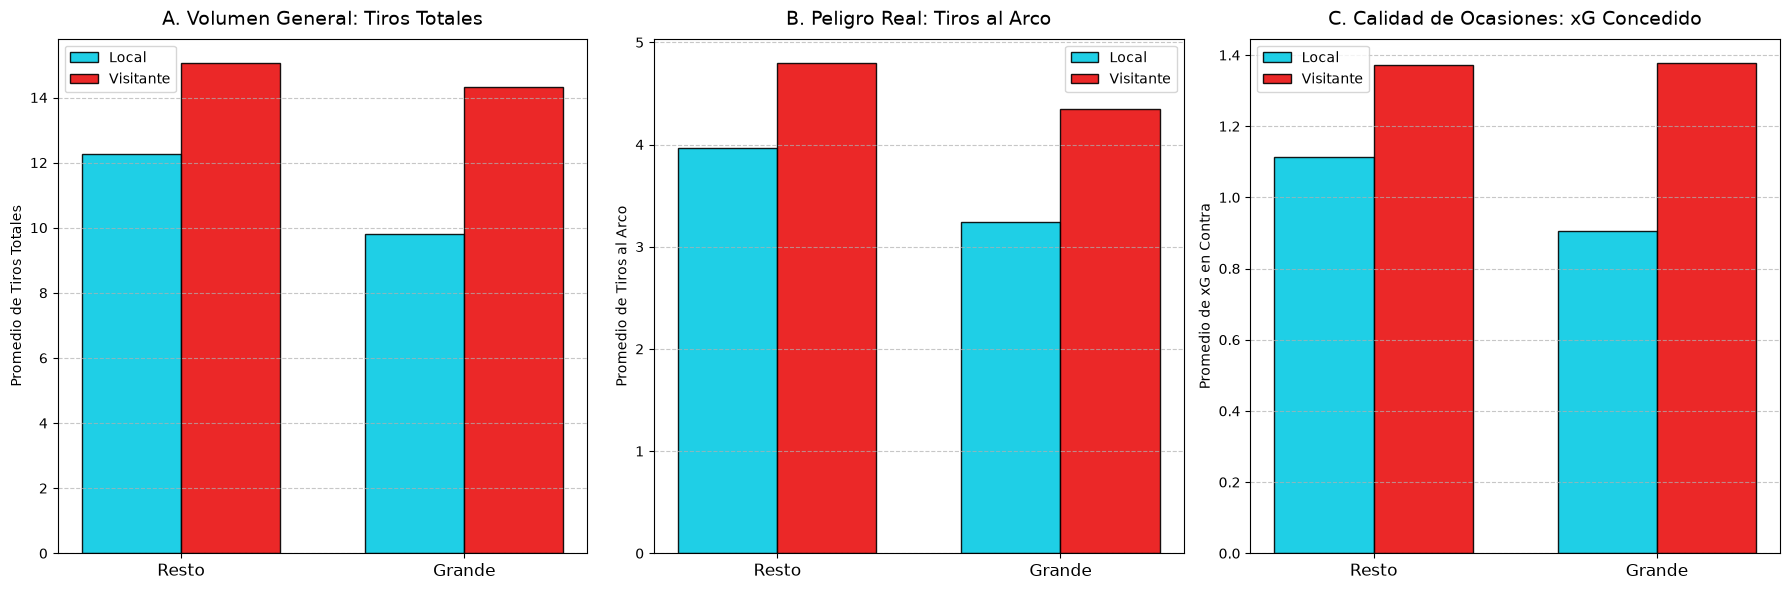

--- Promedios por Jerarquía y Condición ---
                     Tiros Totales Concedidos  Tiros Arco Concedidos  \
Jerarquia Condicion                                                    
Grande    Local                          9.82                   3.24   
          Visitante                     14.31                   4.34   
Resto     Local                         12.28                   3.96   
          Visitante                     15.06                   4.80   

                     xG Concedido  
Jerarquia Condicion                
Grande    Local              0.91  
          Visitante          1.38  
Resto     Local              1.11  
          Visitante          1.37  


In [42]:

# 1. Preparación de la variable Jerarquía
grandes = ['Boca Juniors', 'River Plate', 'Racing Club', 'CA Independiente', 'San Lorenzo']

# Usamos df_defensa (asegurate de haber corrido la celda de la Parte Global antes)
df_defensa['Jerarquia'] = df_defensa['Equipo'].apply(lambda x: 'Grande' if x in grandes else 'Resto')

# 2. Agrupación de datos (calculamos los promedios)
df_agrupado = df_defensa.groupby(['Jerarquia', 'Condicion'])[['Tiros Totales Concedidos', 'Tiros Arco Concedidos', 'xG Concedido']].mean().reset_index()

# Separamos en dos dataframes para facilitar el gráfico de barras agrupadas
df_local_jer = df_agrupado[df_agrupado['Condicion'] == 'Local'].set_index('Jerarquia')
df_visita_jer = df_agrupado[df_agrupado['Condicion'] == 'Visitante'].set_index('Jerarquia')

# Ordenamos para que 'Resto' aparezca a la izquierda y 'Grande' a la derecha
orden = ['Resto', 'Grande']
df_local_jer = df_local_jer.reindex(orden)
df_visita_jer = df_visita_jer.reindex(orden)

# 3. Configuración de los gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ACUALIZADO: Usamos Tiros Totales en el primer gráfico
variables_barras = [
    ('Tiros Totales Concedidos', 'A. Volumen General: Tiros Totales', 'Promedio de Tiros Totales'),
    ('Tiros Arco Concedidos', 'B. Peligro Real: Tiros al Arco', 'Promedio de Tiros al Arco'),
    ('xG Concedido', 'C. Calidad de Ocasiones: xG Concedido', 'Promedio de xG en Contra')
]

x = np.arange(len(orden))  # Posiciones en el eje X (0 y 1)
ancho = 0.35  # Ancho de las barras
colores_barras = ['#06cae4', '#e91010'] # Celeste (Local) y Rojo (Visitante)

# 4. Generación de Barplots (Matplotlib puro)
for i, (columna, titulo, ylabel) in enumerate(variables_barras):
    # Dibujamos las barras de Locales (desplazadas a la izquierda)
    axes[i].bar(x - ancho/2, df_local_jer[columna], ancho, label='Local', 
                color=colores_barras[0], edgecolor='black', alpha=0.9)
    # Dibujamos las barras de Visitantes (desplazadas a la derecha)
    axes[i].bar(x + ancho/2, df_visita_jer[columna], ancho, label='Visitante', 
                color=colores_barras[1], edgecolor='black', alpha=0.9)

    # Formato de títulos y ejes
    axes[i].set_title(titulo, fontsize=14, pad=10)
    axes[i].set_ylabel(ylabel)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(orden, fontsize=12)
    axes[i].legend()
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('analisis_jerarquia_defensa_embudo.png', dpi=300, bbox_inches='tight')
plt.show()

# Imprimir promedios para ver los números exactos
print("--- Promedios por Jerarquía y Condición ---")
print(df_agrupado.set_index(['Jerarquia', 'Condicion']).round(2))

A partir de los resultados expuestos en los gráficos de barras y la tabla de promedios, se observa el impacto de la localía según la jerarquía de los equipos:

* **Promedio de Tiros Totales Concedidos:** En condición de local, los equipos Grandes conceden un promedio de 9.82 remates totales por partido, una cifra inferior a los 12.28 que recibe el Resto. Sin embargo, al jugar de visitante, el promedio de los equipos Grandes asciende a 14.31 tiros totales, acercándose a los 15.06 que promedia el Resto en esa misma condición.

* **Promedio de Tiros al Arco Concedidos:** La tendencia se mantiene al analizar los remates efectivos. Como locales, los equipos Grandes promedian 3.24 tiros al arco recibidos por partido. Al salir de su estadio, esta cifra se incrementa a 4.34, superando el promedio de tiros al arco que recibe el Resto cuando juega en condición de local (3.96).

* **Promedio de xG Concedido:** En sus estadios, los equipos Grandes limitan los Goles Esperados del rival a un promedio de 0.91. Al defender como visitantes, este indicador sube a 1.38 xG. Este valor es estadísticamente equivalente a los 1.37 xG que conceden los equipos del Resto en condición de visitante.

---

> **Conclusión:** Las diferencias estadísticas entre los equipos Grandes y el Resto se observan principalmente en condición de local. Al jugar de visitante, la ventaja de los planteles de mayor jerarquía se diluye, mostrando niveles similares de tiros recibidos y goles esperados en contra que el resto de los equipos de la liga.

### 3. Los 5 Grandes entre sí: Análisis de Rendimiento Individual

En este último apartado, aislaremos a los 5 equipos de mayor envergadura (Boca Juniors, River Plate, Racing Club, Independiente y San Lorenzo) para analizar el comportamiento individual de sus sistemas defensivos.

Se utilizan gráficos de dispersión que cruzan el promedio de las métricas en condición de local (Eje X) frente a la condición de visitante (Eje Y). La línea diagonal punteada representa un rendimiento idéntico en ambas condiciones. Los puntos situados por encima de esta línea indican un deterioro en las estadísticas defensivas al salir del propio estadio.

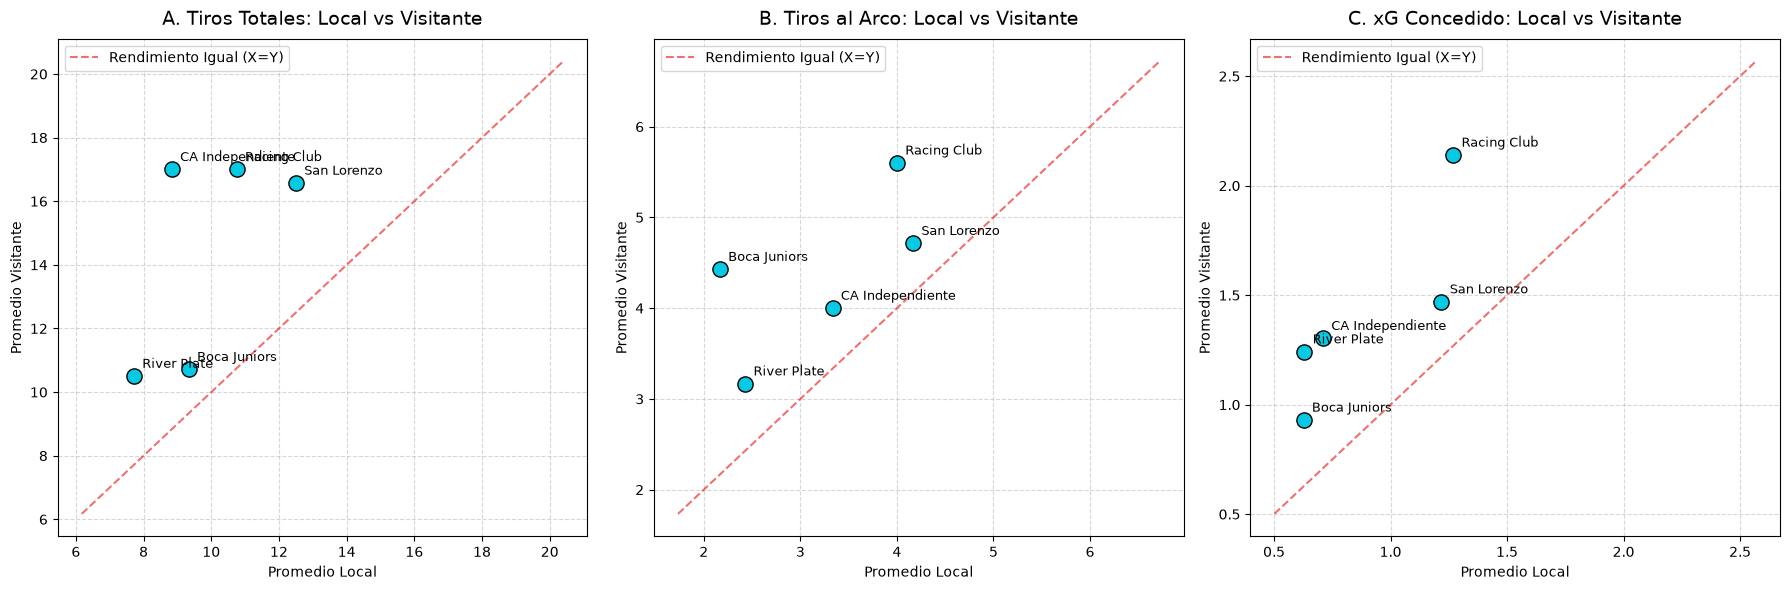

--- Promedios Individuales (Los 5 Grandes) ---
                 Tiros Totales Concedidos           Tiros Arco Concedidos  \
Condicion                           Local Visitante                 Local   
Equipo                                                                      
Boca Juniors                         9.33     10.71                  2.17   
CA Independiente                     8.83     17.00                  3.33   
Racing Club                         10.75     17.00                  4.00   
River Plate                          7.71     10.50                  2.43   
San Lorenzo                         12.50     16.57                  4.17   

                           xG Concedido            
Condicion        Visitante        Local Visitante  
Equipo                                             
Boca Juniors          4.43         0.63      0.93  
CA Independiente      4.00         0.71      1.30  
Racing Club           5.60         1.27      2.14  
River Plate           3.

In [43]:


# 1. Filtrar solo a los 5 Grandes
grandes = ['Boca Juniors', 'River Plate', 'Racing Club', 'CA Independiente', 'San Lorenzo']
df_grandes = df_defensa[df_defensa['Equipo'].isin(grandes)]

# 2. Agrupar por Equipo y Condición, calculando la media
# Usamos unstack() para tener 'Local' y 'Visitante' en distintas columnas y facilitar el ploteo de X e Y
df_g_agrupado = df_grandes.groupby(['Equipo', 'Condicion'])[['Tiros Totales Concedidos', 'Tiros Arco Concedidos', 'xG Concedido']].mean().unstack('Condicion')

# 3. Configuración de los gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

variables_scatter = [
    ('Tiros Totales Concedidos', 'A. Tiros Totales: Local vs Visitante'),
    ('Tiros Arco Concedidos', 'B. Tiros al Arco: Local vs Visitante'),
    ('xG Concedido', 'C. xG Concedido: Local vs Visitante')
]

# 4. Generación de Scatterplots mediante un bucle
for i, (columna, titulo) in enumerate(variables_scatter):
    # Definir ejes X (Local) e Y (Visitante)
    x = df_g_agrupado[(columna, 'Local')]
    y = df_g_agrupado[(columna, 'Visitante')]
    
    # Graficar los puntos
    axes[i].scatter(x, y, color='#06cae4', edgecolor='black', s=120, zorder=5)
    
    # Trazar la línea diagonal de "rendimiento idéntico"
    min_val = min(x.min(), y.min()) * 0.8
    max_val = max(x.max(), y.max()) * 1.2
    axes[i].plot([min_val, max_val], [min_val, max_val], color='#e91010', linestyle='--', alpha=0.6, label='Rendimiento Igual (X=Y)')
    
    # Etiquetar cada punto con el nombre del equipo
    for equipo in df_g_agrupado.index:
        axes[i].annotate(equipo, 
                         (df_g_agrupado.loc[equipo, (columna, 'Local')], 
                          df_g_agrupado.loc[equipo, (columna, 'Visitante')]),
                         xytext=(6, 6), textcoords='offset points', fontsize=9, zorder=10)
                         
    # Formato
    axes[i].set_title(titulo, fontsize=14, pad=10)
    axes[i].set_xlabel('Promedio Local')
    axes[i].set_ylabel('Promedio Visitante')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()

plt.tight_layout()
plt.savefig('analisis_individual_grandes.png', dpi=300, bbox_inches='tight')
plt.show()

# Imprimir la tabla de datos subyacente para redactar el análisis posterior
print("--- Promedios Individuales (Los 5 Grandes) ---")
print(df_g_agrupado.round(2))

### Análisis de Resultados: Comportamiento Individual de los 5 Grandes

A partir de los gráficos de dispersión, que relacionan el promedio de las métricas en condición de local (eje X) frente a la condición de visitante (eje Y), se observa el comportamiento específico de cada uno de los 5 Grandes:

* **Ubicación respecto a la línea de igualdad:** En los tres gráficos (Tiros Totales, Tiros al Arco y xG Concedido), los equipos se posicionan sistemáticamente por encima de la línea diagonal punteada (donde el valor de $Y$ es mayor que el de $X$). Esto demuestra gráficamente que las concesiones defensivas aumentan en todos los clubes al jugar fuera de casa.

* **Volumen de remates (Gráficos A y B):** Al observar la dispersión de los puntos, se evidencia que ningún equipo logra mantener su nivel de restricción de tiros al salir de su estadio. Los puntos sufren un desplazamiento vertical evidente, lo que indica un mayor sufrimiento de remates totales y al arco en condición de visitante, independientemente del club analizado.

* **Calidad de las ocasiones (Gráfico C):** En términos de Goles Esperados (xG) en contra, se observa que aquellos equipos que logran solidez de local (ubicándose por debajo de 1.00 en el eje X), sufren un deterioro marcado de visitante. La dispersión en el eje Y muestra que la calidad de las ocasiones permitidas al rival se incrementa de forma generalizada.

---

> **Conclusión:** El análisis individual ratifica la tendencia observada en los promedios agrupados. Ninguno de los 5 Grandes presenta un sistema defensivo inmune a la localía. El incremento en las llegadas y en la calidad de las ocasiones del rival afecta a todos estos planteles al momento de defender en condición de visitante.